In [1]:
import os
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
DATA_DIR = "../data/chest_xray"

train_dir = os.path.join(DATA_DIR, "train")
val_dir   = os.path.join(DATA_DIR, "val")
test_dir  = os.path.join(DATA_DIR, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5

In [3]:
train_datagen = ImageDataGenerator(rescale=1./255)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.


In [4]:
model_cnn = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 3)),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

In [5]:
model_cnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [7]:
history_cnn = model_cnn.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator
)


Epoch 1/5


163/163 [==============================] - 90s 545ms/step - loss: 0.2621 - accuracy: 0.8942 - val_loss: 0.2726 - val_accuracy: 0.8125
Epoch 2/5
163/163 [==============================] - 85s 520ms/step - loss: 0.1415 - accuracy: 0.9521 - val_loss: 0.4286 - val_accuracy: 0.8125
Epoch 3/5
163/163 [==============================] - 82s 500ms/step - loss: 0.0982 - accuracy: 0.9688 - val_loss: 0.5009 - val_accuracy: 0.7500
Epoch 4/5
163/163 [==============================] - 83s 510ms/step - loss: 0.0762 - accuracy: 0.9728 - val_loss: 0.2080 - val_accuracy: 0.9375
Epoch 5/5
163/163 [==============================] - 83s 510ms/step - loss: 0.0644 - accuracy: 0.9795 - val_loss: 0.1811 - val_accuracy: 0.9375


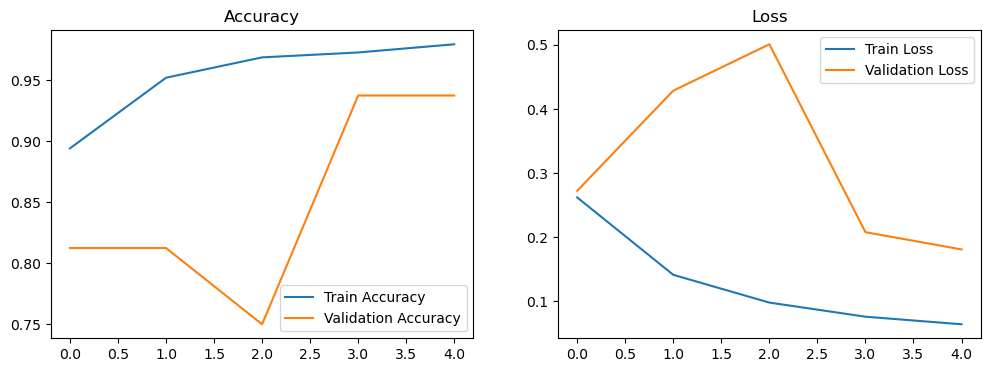

In [8]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history_cnn.history["accuracy"], label="Train Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history_cnn.history["loss"], label="Train Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Loss")

plt.show()


In [9]:
test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

test_loss, test_accuracy = model_cnn.evaluate(test_generator)

print("Test Accuracy :", test_accuracy)
print("Test Loss :", test_loss)


Found 624 images belonging to 2 classes.
20/20 [==============================] - 6s 276ms/step - loss: 0.9309 - accuracy: 0.7708
Test Accuracy : 0.7708333134651184
Test Loss : 0.9308903813362122


In [11]:
import os

os.makedirs("../model", exist_ok=True)


In [12]:
model_cnn.save("../model/cnn_pneumonia_model.keras")

Conclusion du modèle CNN simple

Le modèle CNN simple développé dans cette étape a permis de valider l’ensemble du pipeline de traitement des images, depuis le chargement des données jusqu’à l’évaluation sur un jeu de test indépendant.
Bien que les performances obtenues soient satisfaisantes, avec une accuracy d’environ 77 % sur le jeu de test, le modèle présente certaines limites en termes de généralisation.

Ces résultats mettent en évidence la nécessité d’utiliser des architectures plus avancées, capables d’extraire des caractéristiques plus riches et plus robustes.
Dans la suite de ce projet, un modèle basé sur le transfert d’apprentissage, MobileNetV2, sera utilisé afin d’améliorer les performances et de comparer les deux approches.